In [1]:
import numpy as np
import scipy.linalg as la
import scipy.sparse as sp
from scipy import optimize, stats
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(341)

# LAB 5 – Linear Systems with NumPy

## Q1. Solve 3x + 2y = 12,x + 4y = 10

In [9]:
A = np.array([[3, 2],
              [1, 4]], dtype=float)
b = np.array([12, 10], dtype=float)
sol = np.linalg.solve(A, b)
print("x =", sol[0], ", y =", sol[1])

x = 2.8 , y = 1.7999999999999998


## Q2.A 3 x 3 system with np.linalg.solve()

In [3]:
A3 = np.array([[ 2,  1, -1],
               [-3, -1,  2],
               [-2,  1,  2]], dtype=float)
b3 = np.array([8, -11, -3], dtype=float)
x3 = np.linalg.solve(A3, b3)
print("Solution [x, y, z] =", x3)

Solution [x, y, z] = [ 2.  3. -1.]


## Q3. why np.linalg.solve(A, b) is generally preferred to explicitly calculating 𝐴−1𝑏.

- “np.linalg.solve is preferred because it computes x directly from a factorisation of A, whereas explicit inversion does unnecessary extra work that makes it slower, less accurate and structure-destroying.”

## Q4. Regression of consumption on disposable income (Lusaka households)

In [5]:
X = np.array([30, 45, 60, 100, 150, 200, 240, 250, 300, 320], dtype=float)
Y = np.array([25, 20, 40, 65, 120, 190, 200, 200, 260, 220], dtype=float)


D = np.column_stack([np.ones_like(X), X])
print("Design matrix:\n", D)


beta = np.linalg.solve(D.T @ D, D.T @ Y)
print("\nIntercept (b0) =", beta[0])
print("Slope     (b1) =", beta[1])
print("Fitted model: Y_hat = %.4f + %.4f X" % (beta[0], beta[1]))

print("lstsq check   =", np.linalg.lstsq(D, Y, rcond=None)[0])

Design matrix:
 [[  1.  30.]
 [  1.  45.]
 [  1.  60.]
 [  1. 100.]
 [  1. 150.]
 [  1. 200.]
 [  1. 240.]
 [  1. 250.]
 [  1. 300.]
 [  1. 320.]]

Intercept (b0) = -5.57149367938787
Slope     (b1) = 0.8234306411763296
Fitted model: Y_hat = -5.5715 + 0.8234 X
lstsq check   = [-5.5715  0.8234]


Estimated consumption when X = 181: 143.47


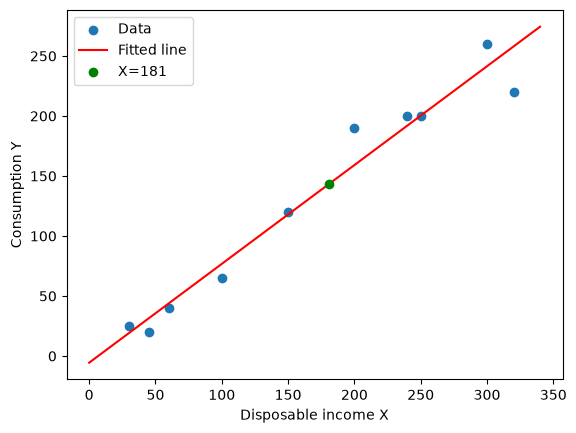

In [6]:
# (ii) Estimated consumption at X = 181
y181 = beta[0] + beta[1]*181
print("Estimated consumption when X = 181:", round(y181, 2))

plt.scatter(X, Y, label="Data")
xs = np.linspace(0, 340, 100)
plt.plot(xs, beta[0] + beta[1]*xs, color="red", label="Fitted line")
plt.scatter([181], [y181], color="green", zorder=5, label="X=181")
plt.xlabel("Disposable income X"); plt.ylabel("Consumption Y"); plt.legend(); plt.show()

**Interpretation:** The slope is the estimated change in consumption for each extra unit of disposable income (the marginal propensity to consume). The predicted consumption at X = 181 is shown above.


# LAB 6 – Matrix Decompositions and Sparse Matrices


## Q1. Covariance matrix and Cholesky decomposition

In [8]:
S = np.array([[4.0, 1.2, 0.5],
              [1.2, 2.3, 0.6],
              [0.5, 0.6, 1.3]])      # symmetric positive definite covariance matrix

L = np.linalg.cholesky(S)            # lower triangular, S = L L^T
print("L:\n", L)
print("Reconstruction S = L @ L.T ?", np.allclose(S, L @ L.T))

L:
 [[2.     0.     0.    ]
 [0.6    1.3928 0.    ]
 [0.25   0.3231 1.0645]]
Reconstruction S = L @ L.T ? True


S is symmetric positive definite, so the Cholesky factor L exists and S = LLᵀ.

## Q2. QR decomposition

In [11]:
M = np.array([[1, 2, 3],
              [4, 5, 6],
              [7, 8, 10]])
Q, R = np.linalg.qr(M)
print("Q:\n", Q)
print("R:\n", R)

Q:
 [[-0.1231  0.9045  0.4082]
 [-0.4924  0.3015 -0.8165]
 [-0.8616 -0.3015  0.4082]]
R:
 [[ -8.124   -9.6011 -11.9399]
 [  0.       0.9045   1.5076]
 [  0.       0.       0.4082]]


## Q3. Reconstruct a matrix using SVD


U, s, Vt = np.linalg.svd(M)
print("Singular values:", s)
M_rec = U @ np.diag(s) @ Vt
print("Reconstructed matrix:\n", M_rec)
print("Equal to original?", np.allclose(M, M_rec))

## Q4. Condition number


In [13]:
print("Condition number of M =", np.linalg.cond(M))

Condition number of M = 88.4482799206987


A condition number near 1 means a well-conditioned problem. A very large value means the matrix is nearly singular, so small changes in the data can cause large changes in the solution.


## Q5. A sparse 1000 × 1000 matrix


In [14]:
S_sparse = sp.random(1000, 1000, density=0.01, format="csr", random_state=341)
print("Shape:", S_sparse.shape)
print("Non-zero entries:", S_sparse.nnz)

Shape: (1000, 1000)
Non-zero entries: 10000


## Q6. Why sparse matrices are useful for large datasets
Most entries in large real-world datasets are zero. A sparse matrix stores only the non-zero values and their positions, so it:
- **Saves memory:** about 0.12 MB instead of 8 MB for the matrix above.
- **Runs faster:** operations only touch the non-zero entries instead of all n² entries.

This makes very large matrices (for example text data, networks and recommender systems) possible to store and compute with.

## LAB 7 - Optimisation and Maximum Likelihood

## Q1. Gradient descnt for f(x) = (x - 10)²

In [16]:
f  = lambda x: (x - 10)**2
df = lambda x: 2*(x - 10)

def gradient_descent(df, x0, lr=0.1, tol=1e-8, max_iter=10000):
    x, path = x0, [x0]
    for _ in range(max_iter):
        x_new = x - lr*df(x)
        path.append(x_new)
        if abs(x_new - x) < tol:
            break
        x = x_new
    return x_new, path

x_min, path = gradient_descent(df, x0=0.0, lr=0.1)
print("Minimiser x* =", round(x_min, 6), "| f(x*) =", f(x_min), "| iterations:", len(path)-1)


Minimiser x* = 10.0 | f(x*) = 1.3729594796773388e-15 | iterations: 87


## Q2. BFGs vs CG on f(x, y) = (x - 4)² + (y - 6)²

In [17]:
g  = lambda p: (p[0]-4)**2 + (p[1]-6)**2
dg = lambda p: np.array([2*(p[0]-4), 2*(p[1]-6)])
x0 = np.array([0.0, 0.0])

for method in ["BFGS", "CG"]:
    r = optimize.minimize(g, x0, jac=dg, method=method)
    print(f"{method:5s} -> x* = {r.x}, f = {r.fun:.2e}, iterations = {r.nit}, "
          f"f-evals = {r.nfev}, grad-evals = {r.njev}, success = {r.success}")

BFGS  -> x* = [4. 6.], f = 1.58e-30, iterations = 3, f-evals = 4, grad-evals = 4, success = True
CG    -> x* = [4. 6.], f = 0.00e+00, iterations = 2, f-evals = 5, grad-evals = 5, success = True


**Comparison:** Both methods find the minimum at (4, 6). BFGS is a quasi-Newton method that builds an approximation of the inverse Hessian (needs O(n²) memory). CG (conjugate gradient) only stores a few vectors, so it needs O(n) memory and suits very large problems. On this simple convex quadratic both converge in very few iterations.


## Q3. Effect of changing the learning rate

lr = 0.01  -> x after 200 iters =         9.8241  (not converged yet)
lr = 0.1   -> x after  87 iters =        10.0000  (converged)
lr = 0.5   -> x after   2 iters =        10.0000  (converged)
lr = 0.9   -> x after  97 iters =        10.0000  (converged)
lr = 1.0   -> x after 200 iters =         0.0000  (not converged yet)
lr = 1.05  -> x after 200 iters = -1899052754.6047  (diverged)


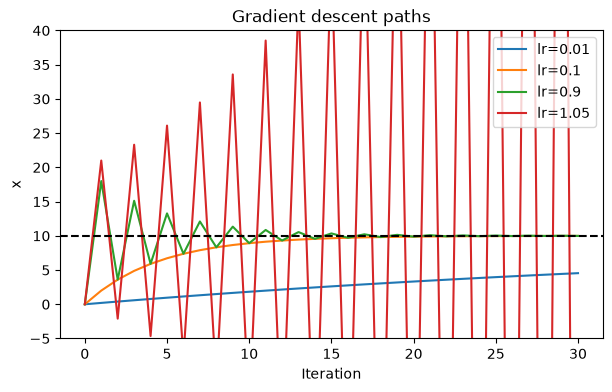

In [18]:
for lr in [0.01, 0.1, 0.5, 0.9, 1.0, 1.05]:
    x, p = gradient_descent(df, x0=0.0, lr=lr, max_iter=200)
    status = "diverged" if abs(x) > 1e6 else "converged" if abs(x-10) < 1e-3 else "not converged yet"
    print(f"lr = {lr:<5} -> x after {len(p)-1:>3} iters = {x:>14.4f}  ({status})")

plt.figure(figsize=(7,4))
for lr in [0.01, 0.1, 0.9, 1.05]:
    _, p = gradient_descent(df, 0.0, lr=lr, max_iter=30)
    plt.plot(p, label=f"lr={lr}")
plt.axhline(10, color="k", ls="--"); plt.ylim(-5, 40)
plt.xlabel("Iteration"); plt.ylabel("x"); plt.legend(); plt.title("Gradient descent paths"); plt.show()

**Explanation:** For this function the update is x ← x − lr·2(x − 10), so the error is multiplied by (1 − 2·lr) each step.
- **Too small** (0.01): converges, but very slowly.
- **Moderate** (0.1–0.5): fast, stable convergence. At lr = 0.5 it lands on 10 in a single step.
- **Near the limit** (0.9): the iterates oscillate around 10 while shrinking.
- **Too large** (≥ 1.0): the error no longer shrinks, so the iterates oscillate forever (lr = 1) or diverge (lr > 1).

## Q4. MLE of the mean of normal observations (SciPy)

In [19]:
obs = rng.normal(loc=25, scale=4, size=500)

def neg_loglik(params):
    mu, log_sigma = params            # optimise log(sigma) to keep sigma > 0
    return -np.sum(stats.norm.logpdf(obs, loc=mu, scale=np.exp(log_sigma)))

res = optimize.minimize(neg_loglik, x0=[0.0, 0.0], method="BFGS")
mu_hat, sigma_hat = res.x[0], np.exp(res.x[1])
print("MLE  mu_hat    =", mu_hat)
print("Sample mean    =", obs.mean(), "(they agree)")
print("MLE  sigma_hat =", sigma_hat, "| np.std (ddof=0) =", obs.std())
print("Via stats.norm.fit:", stats.norm.fit(obs))

MLE  mu_hat    = 24.679392064558368
Sample mean    = 24.679391926551933 (they agree)
MLE  sigma_hat = 4.052718445880574 | np.std (ddof=0) = 4.052718501282031
Via stats.norm.fit: (np.float64(24.679391926551933), np.float64(4.052718501282031))


The MLE of μ is the sample mean, and the MLE of σ uses divisor n (not n − 1).

## Q5. Sigmoid function

[0.     0.1192 0.5    0.8808 1.    ]


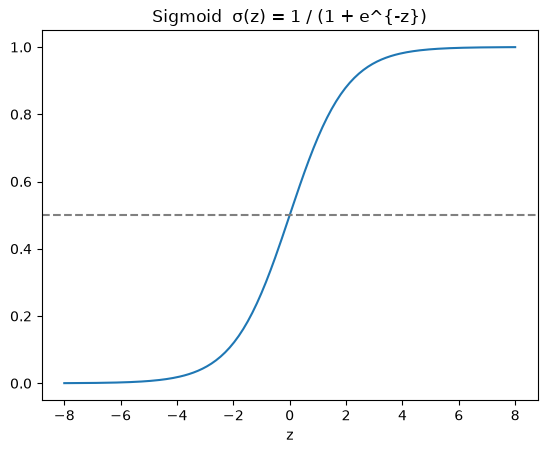

In [21]:
def sigmoid(z):
    z = np.asarray(z, dtype=float)
    return np.where(z >= 0, 1/(1 + np.exp(-np.abs(z))), np.exp(-np.abs(z))/(1 + np.exp(-np.abs(z))))  # overflow-safe

print(sigmoid(np.array([-10, -2, 0, 2, 10])))
zs = np.linspace(-8, 8, 200)
plt.plot(zs, sigmoid(zs)); plt.axhline(0.5, ls="--", color="grey")
plt.title("Sigmoid  σ(z) = 1 / (1 + e^{-z})"); plt.xlabel("z"); plt.show()

## Q6. Simple logistic regression by MLE (study hours vs pass/fail)

In [22]:
hours = np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float)
passed = np.array([0, 0, 0, 0, 1, 1, 1, 1], dtype=float)

def nll(beta, X=hours, Y=passed):
    z = beta[0] + beta[1]*X
    # -loglik = sum[ log(1+e^z) - y z ]  (numerically stable form)
    return np.sum(np.logaddexp(0, z) - Y*z)

res = optimize.minimize(nll, x0=[0.0, 0.0], method="BFGS")
print("Unpenalised MLE:", res.x, "| NLL =", res.fun)
print("Message:", res.message)

Unpenalised MLE: [-127.8189   28.1855] | NLL = 2.3108353976701068e-06
Message: Optimization terminated successfully.


**Note:** the data are perfectly separated (everyone with X ≤ 4 fails, everyone with X ≥ 5 passes), so the likelihood keeps increasing as the slope grows and a finite MLE does not exist. The large coefficients above are just where the optimiser stopped. A small L2 (ridge) penalty gives finite, stable estimates:

Penalised fit: b0 = -9.3942, b1 = 2.0876
Decision boundary (P=0.5) at X = 4.499999892316124
P(pass | 2 hours) = 0.0054
P(pass | 4 hours) = 0.2604
P(pass | 4.5 hours) = 0.5000
P(pass | 5 hours) = 0.7396
P(pass | 7 hours) = 0.9946


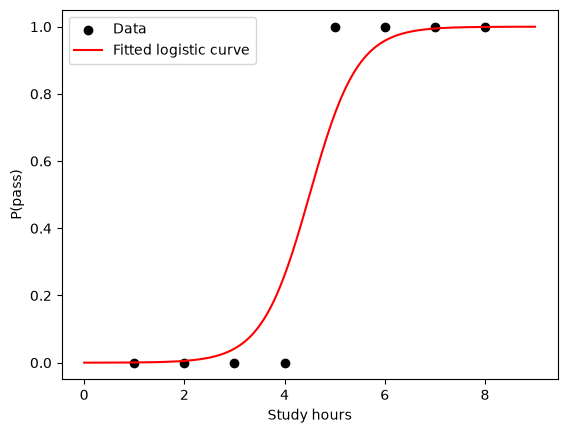

In [23]:
lam = 0.1
pen = lambda b: nll(b) + lam*b[1]**2
res_p = optimize.minimize(pen, x0=[0.0, 0.0], method="BFGS")
b0, b1 = res_p.x
print(f"Penalised fit: b0 = {b0:.4f}, b1 = {b1:.4f}")
print("Decision boundary (P=0.5) at X =", -b0/b1)
for h in [2, 4, 4.5, 5, 7]:
    print(f"P(pass | {h} hours) = {sigmoid(b0 + b1*h):.4f}")

xs = np.linspace(0, 9, 200)
plt.scatter(hours, passed, color="black", label="Data")
plt.plot(xs, sigmoid(b0 + b1*xs), color="red", label="Fitted logistic curve")
plt.xlabel("Study hours"); plt.ylabel("P(pass)"); plt.legend(); plt.show()

# LAB 8 – Simulation and Monte Carlo Methods


## Q1. 10 000 observations from N(50, 10²)


Sample mean = 50.224748599613 (true 50)
Sample sd   = 9.910405290306283 (true 10)


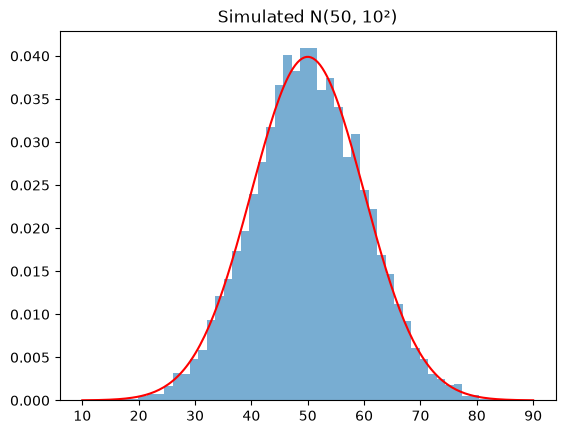

In [26]:
x = rng.normal(loc=50, scale=10, size=10_000)
print("Sample mean =", x.mean(), "(true 50)")
print("Sample sd   =", x.std(ddof=1), "(true 10)")
plt.hist(x, bins=50, density=True, alpha=0.6)
t = np.linspace(10, 90, 200); plt.plot(t, stats.norm.pdf(t, 50, 10), "r")
plt.title("Simulated N(50, 10²)"); plt.show()

## Q2. 10 000 Bernoulli(p = 0.3) observations


In [28]:
b = rng.binomial(n=1, p=0.3, size=10_000)
print("Sample proportion of successes =", b.mean(), "(true p = 0.3)")

Sample proportion of successes = 0.3092 (true p = 0.3)


## Q3. Monte Carlo estimate of ∫₀¹ x³ dx


In [29]:
N = 1_000_000
u = rng.uniform(0, 1, N)
vals = u**3
est = vals.mean()
se = vals.std(ddof=1)/np.sqrt(N)
print(f"Estimate = {est:.5f} ± {1.96*se:.5f} (95% CI) | exact = 1/4 = 0.25")

Estimate = 0.24971 ± 0.00056 (95% CI) | exact = 1/4 = 0.25


## Q4. Estimate π using one million points


In [30]:
N = 1_000_000
px, py = rng.uniform(0, 1, N), rng.uniform(0, 1, N)
inside = (px**2 + py**2) <= 1
pi_hat = 4*inside.mean()
print("pi estimate =", pi_hat, "| error =", abs(pi_hat - np.pi))


pi estimate = 3.139944 | error = 0.0016486535897932697


Points are uniform in the unit square; the proportion falling inside the quarter circle estimates π/4, so π ≈ 4 × proportion.


## Q5. Estimate P(X > 1.96), X ~ N(0, 1)


In [31]:
z = rng.standard_normal(1_000_000)
p_mc = (z > 1.96).mean()
print("Monte Carlo estimate =", p_mc)
print("Exact value          =", stats.norm.sf(1.96), "(≈ 0.025)")

Monte Carlo estimate = 0.025047
Exact value          = 0.024997895148220435 (≈ 0.025)


## Q6. Importance sampling for E(X²), X ~ U(0, 1)


In [32]:
N = 100_000
v = np.sqrt(rng.uniform(0, 1, N))   # draws from the proposal g(x) = 2x
w = 1 / (2*v)                       # weight f(x)/g(x), where f(x) = 1 on (0,1)
est = np.mean(v**2 * w)             # average of x² × weight
print("Importance sampling estimate =", est, "| true value = 1/3")

Importance sampling estimate = 0.3330930820972877 | true value = 1/3


## Q7. Difference between importance sampling and control variates

Both are variance-reduction techniques. They keep the Monte Carlo estimate unbiased but make it more precise, so the same accuracy needs fewer simulated points. The difference is in how they reduce the variance.

**Importance sampling** changes the distribution we sample from. To estimate E[h(X)] = ∫ h(x) f(x) dx, where X has density f, we instead draw X₁, …, X_N from a different density g that puts more draws in the region that matters most for h. Each draw is then corrected with a weight so the estimate stays unbiased:

θ̂_IS = (1/N) Σ h(Xᵢ) · f(Xᵢ) / g(Xᵢ),  with Xᵢ ~ g

The variance is smallest when g is roughly proportional to the product h(x)f(x). The requirement is that g(x) > 0 wherever h(x)f(x) ≠ 0. A poorly chosen g can make the weights huge and the variance very large, or even infinite.

**Control variates** keep the original sampling distribution and change the quantity being averaged. We pick a second quantity C that is strongly correlated with h(X) and whose true mean E[C] is known exactly. Then we subtract the part of the noise that C explains:

θ̂_CV = (1/N) Σ [ h(Xᵢ) − c · (Cᵢ − E[C]) ]

The best coefficient is c = Cov(h, C) / Var(C). The stronger the correlation between h(X) and C, the larger the variance reduction. If the correlation is weak, there is little or no gain.

**In short:** importance sampling improves the estimate by sampling from a better distribution and reweighting. Control variates improve it by sampling from the original distribution and subtracting a correlated term with a known mean. Importance sampling needs a good choice of g, while control variates need a good control with a known expectation.